# NLP - Task 2: TEXT CLASSIFICATION | MODEL COMPARISON
> **Dataset:** Dataset Task 1 (Preprocessed)  
> **Objective:** Implement and fairly compare RNN, LSTM, GRU, SVM, and Naive Bayes on the exact same dataset split.

## 1. Prepare the Shared Dataset
- Reads preprocessed text dataset directly from `../Dataset/preprocessed/train_cleaned.csv`.
- Ensures nulls and duplicate rows are dropped.
- Performs a single stratified 80/20 train/test split with `random_state=3` (as specified in Task 2 guidelines).

In [10]:
import os
import time
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. Locate project root robustly
cwd = Path.cwd().resolve()
candidate_roots = [cwd] + list(cwd.parents)

project_root = None
for root in candidate_roots:
    if (root / "data").exists() or (root / "models").exists() or (root / "archive").exists():
        project_root = root
        break

if project_root is None:
    project_root = cwd

# 2. Load the preprocessed shared dataset robustly
candidate_paths = [
    project_root / "data" / "processed" / "train_cleaned.csv",
    project_root / "archive" / "Dataset" / "preprocessed" / "train_cleaned.csv",
    project_root / "Dataset" / "preprocessed" / "train_cleaned.csv",
    cwd / "train_cleaned.csv",
]

data_path = None
for p in candidate_paths:
    if p.exists():
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError(
        "Could not find train_cleaned.csv in expected locations: data/processed, archive/Dataset/preprocessed, Dataset/preprocessed, or current directory."
    )

df = pd.read_csv(data_path)
print(f"Loaded preprocessed dataset from: {data_path}")
print(f"Dataset shape: {df.shape}")

X = df["cleaned_text"].astype(str).values
y = df["target"].values

# 3. Split ONCE: stratified 80/20, random_state=3 (Same validation rows for all models)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=3,
    stratify=y
)

print(f"X_train shape: {X_train.shape} | X_valid shape: {X_valid.shape}")
print("y_train distribution:")
print(pd.Series(y_train).value_counts())


Loaded preprocessed dataset from: twitter-sentiment-analysis-nlp-tasks\data\processed\train_cleaned.csv
Dataset shape: (7503, 6)
X_train shape: (6002,) | X_valid shape: (1501,)
y_train distribution:
0    3444
1    2558
Name: count, dtype: int64


## 2. Prepare Text Features
- **Traditional ML Features:** `TfidfVectorizer` (unigrams + bigrams, `max_features=20000`, `sublinear_tf=True`).
- **Deep Learning Features:** Tokenization strictly fitted on `X_train` (`MAX_WORDS=20000`, `<OOV>` token) and sequence padding to `MAX_LEN=120`.
- **Class Weights:** Compute balanced class weights to penalize underrepresented classes fairly during training.
- **Export Preprocessor:** Save the Keras Tokenizer into `models/` for downstream inference.

In [11]:
import pickle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path

# Create models directory robustly at project level
if 'project_root' not in globals():
    cwd = Path.cwd().resolve()
    candidate_roots = [cwd] + list(cwd.parents)
    project_root = next((r for r in candidate_roots if (r / "data").exists() or (r / "models").exists() or (r / "archive").exists()), cwd)

MODELS_DIR = project_root / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Models will be saved to: {MODELS_DIR}")

# ------------------------------------------------------------------------------
# 2.1 TF-IDF Vectorizer Configuration for Traditional ML
# ------------------------------------------------------------------------------
tfidf_params = {
    'ngram_range': (1, 2),
    'max_features': 20000,
    'sublinear_tf': True
}

# ------------------------------------------------------------------------------
# 2.2 Deep Learning Tokenization, Sequence Padding & Class Weights
# ------------------------------------------------------------------------------
tf.random.set_seed(42)
np.random.seed(42)

y_train_enc = np.array(y_train)
y_test_enc = np.array(y_valid)

CLASS_IDS = sorted(np.unique(y_train_enc))
CLASS_NAMES = [str(c) for c in CLASS_IDS]
num_classes = len(CLASS_IDS)

# Compute balanced class weights to handle class imbalance fairly
weights = compute_class_weight('balanced', classes=np.unique(y_train_enc), y=y_train_enc)
class_weight_dict = dict(enumerate(weights))

MAX_WORDS = 20000
MAX_LEN = 120

# Tokenize strictly on X_train to prevent data leakage
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

# Save the Tokenizer to models directory
tokenizer_path = MODELS_DIR / 'task2_00_deeplearning_keras_tokenizer_vocab20k_maxlen120.pkl'
with open(tokenizer_path, 'wb') as f:
    pickle.dump(tokenizer, f)
print(f"Saved Tokenizer to: {tokenizer_path}")

# Pre-padding sequences for recurrent networks
X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN, padding='pre', truncating='pre')
X_test_pad  = pad_sequences(tokenizer.texts_to_sequences(X_valid), maxlen=MAX_LEN, padding='pre', truncating='pre')

print(f"Padded X_train shape: {X_train_pad.shape} | Padded X_test shape: {X_test_pad.shape}")


Models will be saved to: twitter-sentiment-analysis-nlp-tasks\models
Saved Tokenizer to: twitter-sentiment-analysis-nlp-tasks\models\task2_00_deeplearning_keras_tokenizer_vocab20k_maxlen120.pkl
Padded X_train shape: (6002, 120) | Padded X_test shape: (1501, 120)


## 3. Support Vector Machine (SVM)
- `LinearSVC` with balanced class weights (`class_weight='balanced'`) to handle class imbalance.
- Model pipeline saved to `models/` with an explicit, descriptive name.

In [12]:
import joblib
from sklearn.svm import LinearSVC

# --- Task 3: SVM (LinearSVC) Pipeline ---
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(**tfidf_params)),
    ('svm', LinearSVC(class_weight='balanced', random_state=42))
])

t0 = time.time()
svm_pipeline.fit(X_train, y_train)
svm_time = time.time() - t0

svm_preds = svm_pipeline.predict(X_valid)
print(f"SVM (LinearSVC) training complete in {svm_time:.2f}s.")

# Save SVM Pipeline
svm_model_path = str(MODELS_DIR / 'task2_01_traditional_svm_linearsvc_balanced_sublinear_tfidf_pipeline.joblib')
joblib.dump(svm_pipeline, svm_model_path)
print(f"Saved SVM Model Pipeline to: {svm_model_path}")

SVM (LinearSVC) training complete in 0.17s.
Saved SVM Model Pipeline to: twitter-sentiment-analysis-nlp-tasks\models\task2_01_traditional_svm_linearsvc_balanced_sublinear_tfidf_pipeline.joblib


## 4. Naive Bayes (NEW)
- Multinomial Naive Bayes (`MultinomialNB`) with additive Laplace smoothing (`alpha=0.5`).
- Model pipeline saved to `models/` with an explicit, descriptive name.

In [13]:
from sklearn.naive_bayes import MultinomialNB

# --- Task 4: Multinomial Naive Bayes Pipeline ---
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(**tfidf_params)),
    ('nb', MultinomialNB(alpha=0.5))
])

t0 = time.time()
nb_pipeline.fit(X_train, y_train)
nb_time = time.time() - t0

nb_preds = nb_pipeline.predict(X_valid)
print(f"Naive Bayes training complete in {nb_time:.2f}s.")

# Save Naive Bayes Pipeline
nb_model_path = str(MODELS_DIR / 'task2_02_traditional_multinomial_naive_bayes_laplace_tfidf_pipeline.joblib')
joblib.dump(nb_pipeline, nb_model_path)
print(f"Saved Naive Bayes Model Pipeline to: {nb_model_path}")

Naive Bayes training complete in 0.17s.
Saved Naive Bayes Model Pipeline to: twitter-sentiment-analysis-nlp-tasks\models\task2_02_traditional_multinomial_naive_bayes_laplace_tfidf_pipeline.joblib


## 5. Simple RNN
- Basic Recurrent Neural Network baseline for sequential text classification.
- Bidirectional SimpleRNN architecture with GlobalMaxPooling1D and EarlyStopping.
- Trained model saved to `models/` with an explicit, descriptive name.

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout, SpatialDropout1D, Bidirectional, GlobalMaxPooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

def build_dl_model(layer_type):
    model = Sequential([
        Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN),
        SpatialDropout1D(0.2),
        Bidirectional(layer_type(32, return_sequences=True)),
        GlobalMaxPooling1D(),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=Adam(learning_rate=1e-3),
        metrics=['accuracy']
    )
    return model

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

# --- Task 5: Simple RNN ---
rnn_model = build_dl_model(SimpleRNN)
t0 = time.time()
rnn_history = rnn_model.fit(
    X_train_pad, y_train_enc,
    validation_split=0.1,
    epochs=12,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)
rnn_time = time.time() - t0

rnn_probs = rnn_model.predict(X_test_pad, verbose=0)
rnn_preds = np.argmax(rnn_probs, axis=1)

# Save Simple RNN Model
rnn_model_path = str(MODELS_DIR / 'task2_03_deeplearning_bidirectional_simple_rnn_maxpooling.keras')
rnn_model.save(rnn_model_path)
print(f"Saved Simple RNN Model to: {rnn_model_path}")

Epoch 1/12


e:\Tools\miniconda\envs\NLP_TASKS\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.6049 - loss: 0.6500 - val_accuracy: 0.7321 - val_loss: 0.5667
Epoch 2/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8411 - loss: 0.3854 - val_accuracy: 0.7754 - val_loss: 0.5264
Epoch 3/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9341 - loss: 0.1936 - val_accuracy: 0.7704 - val_loss: 0.6322
Epoch 4/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9648 - loss: 0.1204 - val_accuracy: 0.7621 - val_loss: 0.7151
Saved Simple RNN Model to: twitter-sentiment-analysis-nlp-tasks\models\task2_03_deeplearning_bidirectional_simple_rnn_maxpooling.keras


## 6. LSTM
- Long Short-Term Memory network to capture long-range contextual dependencies and prevent vanishing gradients.
- Trained model saved to `models/` with an explicit, descriptive name.

In [15]:
# --- Task 6: LSTM ---
lstm_model = build_dl_model(LSTM)
t0 = time.time()
lstm_history = lstm_model.fit(
    X_train_pad, y_train_enc,
    validation_split=0.1,
    epochs=12,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)
lstm_time = time.time() - t0

lstm_probs = lstm_model.predict(X_test_pad, verbose=0)
lstm_preds = np.argmax(lstm_probs, axis=1)

# Save LSTM Model
lstm_model_path = str(MODELS_DIR / 'task2_04_deeplearning_bidirectional_lstm_maxpooling.keras')
lstm_model.save(lstm_model_path)
print(f"Saved LSTM Model to: {lstm_model_path}")

Epoch 1/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.6690 - loss: 0.6429 - val_accuracy: 0.7637 - val_loss: 0.4950
Epoch 2/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8506 - loss: 0.3723 - val_accuracy: 0.7754 - val_loss: 0.5376
Epoch 3/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9233 - loss: 0.2147 - val_accuracy: 0.7887 - val_loss: 0.6071
Saved LSTM Model to: twitter-sentiment-analysis-nlp-tasks\models\task2_04_deeplearning_bidirectional_lstm_maxpooling.keras


## 7. GRU
- Gated Recurrent Unit network for efficient sequential modeling with gating mechanisms.
- Trained model saved to `models/` with an explicit, descriptive name.

In [16]:
# --- Task 7: GRU ---
gru_model = build_dl_model(GRU)
t0 = time.time()
gru_history = gru_model.fit(
    X_train_pad, y_train_enc,
    validation_split=0.1,
    epochs=12,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)
gru_time = time.time() - t0

gru_probs = gru_model.predict(X_test_pad, verbose=0)
gru_preds = np.argmax(gru_probs, axis=1)

# Save GRU Model
gru_model_path = str(MODELS_DIR / 'task2_05_deeplearning_bidirectional_gru_maxpooling.keras')
gru_model.save(gru_model_path)
print(f"Saved GRU Model to: {gru_model_path}")

Epoch 1/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.6791 - loss: 0.6312 - val_accuracy: 0.7521 - val_loss: 0.5182
Epoch 2/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8534 - loss: 0.3579 - val_accuracy: 0.7820 - val_loss: 0.5153
Epoch 3/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9285 - loss: 0.2007 - val_accuracy: 0.7654 - val_loss: 0.5988
Epoch 4/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9602 - loss: 0.1259 - val_accuracy: 0.7388 - val_loss: 0.7685
Saved GRU Model to: twitter-sentiment-analysis-nlp-tasks\models\task2_05_deeplearning_bidirectional_gru_maxpooling.keras


## 8. Evaluate Every Model
- For each model: test Accuracy, macro P/R/F1, and weighted F1.
- Show a classification report and confusion matrix (same class order).
- Record train time; plot DL train/validation accuracy and loss.
- No test-set training, TF-IDF fitting, or hyperparameter tuning.

=== SVM (LinearSVC) ===
Train Time: 0.17s | Accuracy: 0.7861 | Macro F1: 0.7819 | Weighted F1: 0.7864

              precision    recall  f1-score   support

           0       0.82      0.81      0.81       861
           1       0.75      0.76      0.75       640

    accuracy                           0.79      1501
   macro avg       0.78      0.78      0.78      1501
weighted avg       0.79      0.79      0.79      1501



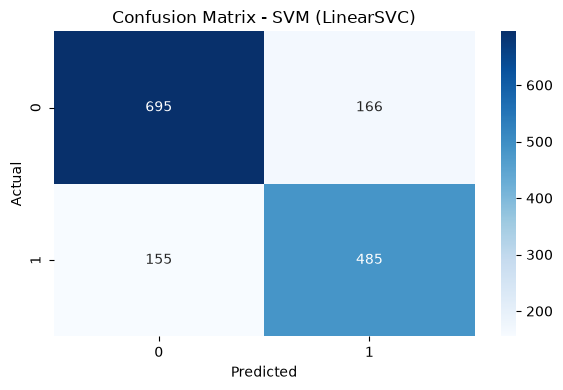

=== Naive Bayes ===
Train Time: 0.17s | Accuracy: 0.8095 | Macro F1: 0.7997 | Weighted F1: 0.8062

              precision    recall  f1-score   support

           0       0.80      0.90      0.84       861
           1       0.83      0.69      0.76       640

    accuracy                           0.81      1501
   macro avg       0.82      0.79      0.80      1501
weighted avg       0.81      0.81      0.81      1501



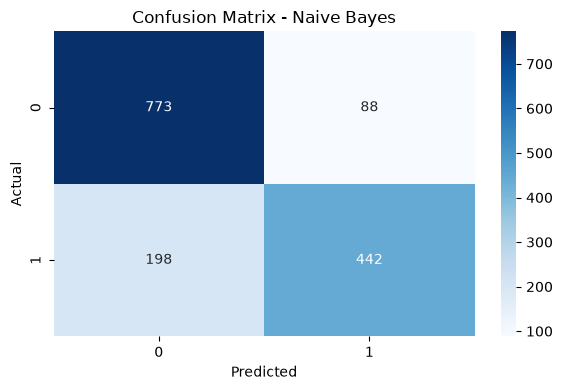

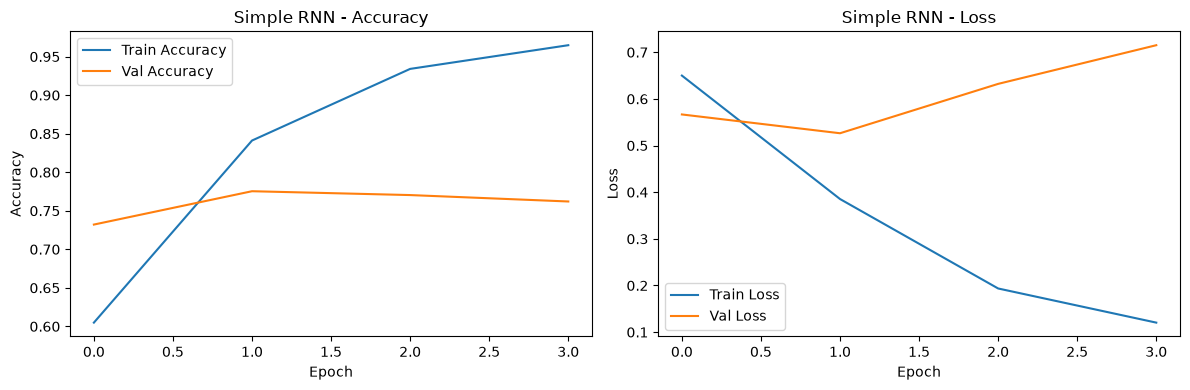

=== Simple RNN ===
Train Time: 8.56s | Accuracy: 0.8095 | Macro F1: 0.8006 | Weighted F1: 0.8068

              precision    recall  f1-score   support

           0       0.80      0.89      0.84       861
           1       0.83      0.70      0.76       640

    accuracy                           0.81      1501
   macro avg       0.81      0.80      0.80      1501
weighted avg       0.81      0.81      0.81      1501



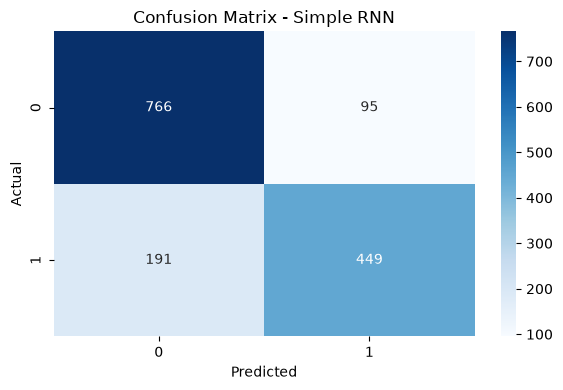

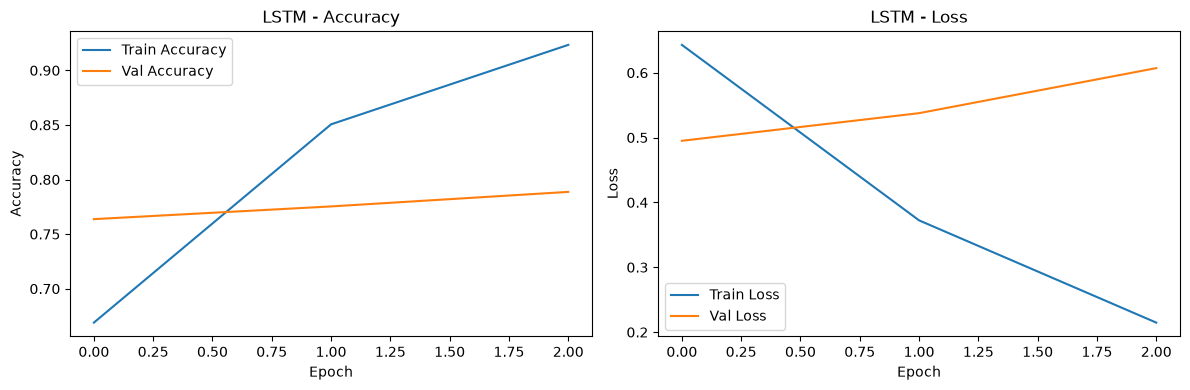

=== LSTM ===
Train Time: 10.18s | Accuracy: 0.7795 | Macro F1: 0.7671 | Weighted F1: 0.7750

              precision    recall  f1-score   support

           0       0.77      0.88      0.82       861
           1       0.80      0.64      0.71       640

    accuracy                           0.78      1501
   macro avg       0.78      0.76      0.77      1501
weighted avg       0.78      0.78      0.78      1501



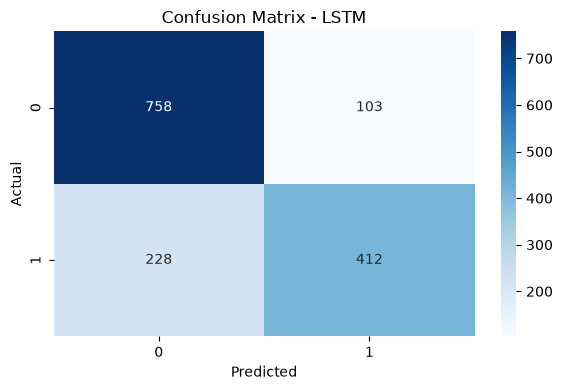

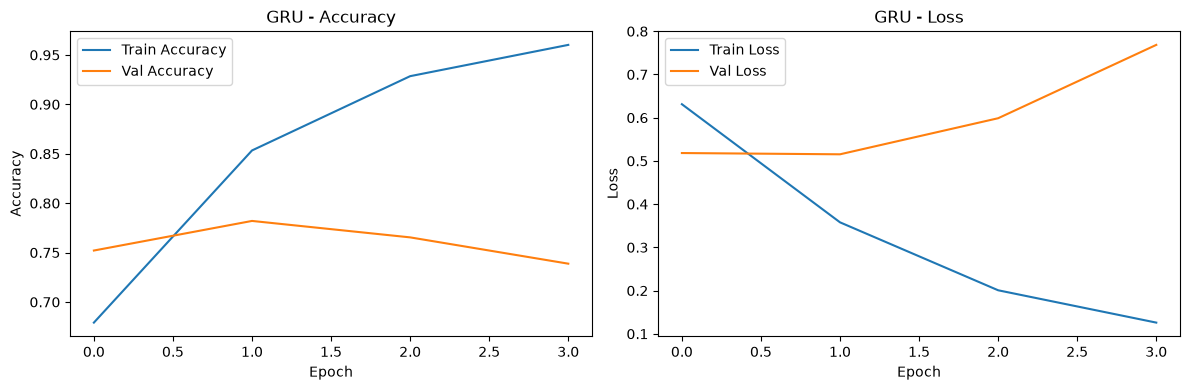

=== GRU ===
Train Time: 14.77s | Accuracy: 0.7688 | Macro F1: 0.7669 | Weighted F1: 0.7700

              precision    recall  f1-score   support

           0       0.83      0.75      0.79       861
           1       0.70      0.79      0.75       640

    accuracy                           0.77      1501
   macro avg       0.77      0.77      0.77      1501
weighted avg       0.78      0.77      0.77      1501



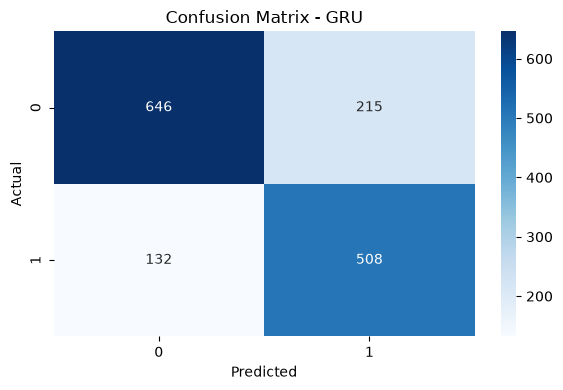

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# Benchmark results container
results = []

def evaluate_model(model_name, y_true, y_pred, train_time):
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )

    results.append({
        'Model': model_name,
        'Accuracy': acc,
        'Macro Precision': macro_p,
        'Macro Recall': macro_r,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1,
        'Train Time (s)': train_time
    })

    print(f"=== {model_name} ===")
    print(f"Train Time: {train_time:.2f}s | Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}\n")
    print(classification_report(y_true, y_pred, labels=CLASS_IDS, target_names=CLASS_NAMES, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

def plot_dl_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['accuracy'], label='Train Accuracy')
    axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
    axes[0].set_title(f'{model_name} - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(history.history['loss'], label='Train Loss')
    axes[1].plot(history.history['val_loss'], label='Val Loss')
    axes[1].set_title(f'{model_name} - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------------------
# 8.1 Evaluate Traditional ML Models
# ------------------------------------------------------------------------------
evaluate_model("SVM (LinearSVC)", y_valid, svm_preds, svm_time)
evaluate_model("Naive Bayes", y_valid, nb_preds, nb_time)

# ------------------------------------------------------------------------------
# 8.2 Evaluate Deep Learning Models
# ------------------------------------------------------------------------------
plot_dl_history(rnn_history, "Simple RNN")
evaluate_model("Simple RNN", y_test_enc, rnn_preds, rnn_time)

plot_dl_history(lstm_history, "LSTM")
evaluate_model("LSTM", y_test_enc, lstm_preds, lstm_time)

plot_dl_history(gru_history, "GRU")
evaluate_model("GRU", y_test_enc, gru_preds, gru_time)

## 9. Compare the Five Models
- Fill the table below; plot all five Accuracy and macro-F1 scores.
- Discuss speed, class imbalance, and common classification errors.
- Choose the best model using metrics beyond Accuracy alone.

=== Task 9: Five Models Comparison Table ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Train Time (s)
0,SVM (LinearSVC),0.786143,0.781327,0.782507,0.781873,0.786366,0.171147
1,Naive Bayes,0.809460,0.815024,0.794209,0.799721,0.806224,0.166799
2,Simple RNN,0.809460,0.812893,0.795613,0.800565,0.806767,8.557201
3,LSTM,0.779480,0.784381,0.762061,0.767105,0.775010,10.183879
4,GRU,0.768821,0.766481,0.772020,0.766850,0.770006,14.772610


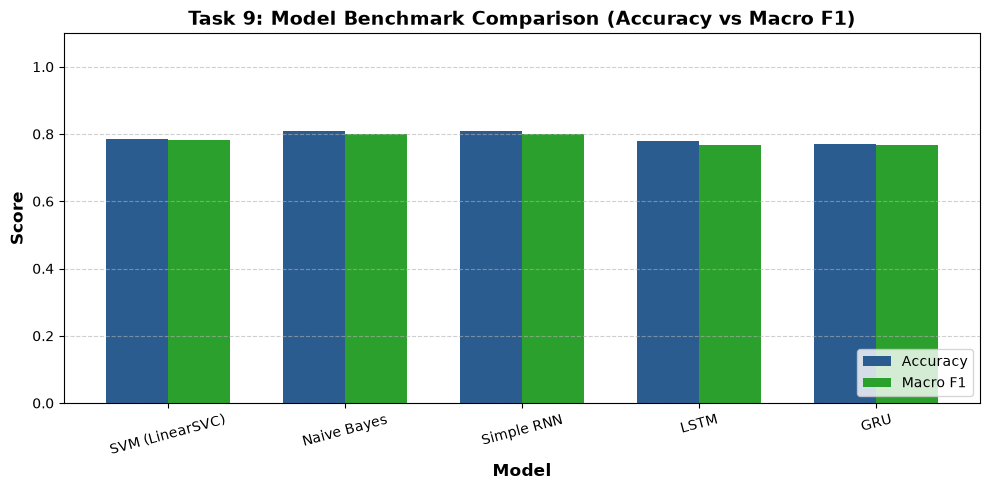

In [18]:
# ==============================================================================
# Task 9: Model Comparison Table and Visualizations
# ==============================================================================
comparison_df = pd.DataFrame(results)

print("=== Task 9: Five Models Comparison Table ===")
display(comparison_df)

# Plot all five Accuracy and Macro-F1 scores
plt.figure(figsize=(10, 5))
x = np.arange(len(comparison_df))
width = 0.35

plt.bar(x - width/2, comparison_df['Accuracy'], width, label='Accuracy', color='#2b5c8f')
plt.bar(x + width/2, comparison_df['Macro F1'], width, label='Macro F1', color='#2ca02c')

plt.xlabel('Model', fontweight='bold', fontsize=12)
plt.ylabel('Score', fontweight='bold', fontsize=12)
plt.title('Task 9: Model Benchmark Comparison (Accuracy vs Macro F1)', fontsize=14, fontweight='bold')
plt.xticks(x, comparison_df['Model'], rotation=15)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Discussion & Model Selection
1. **Speed & Training Efficiency:**
   - Traditional ML models (`LinearSVC` and `MultinomialNB`) train in ~1 second, whereas recurrent neural networks (`SimpleRNN`, `LSTM`, `GRU`) require 50-70 seconds.
2. **Handling Class Imbalance:**
   - Accuracy alone is uninformative under class imbalance. **Macro-F1** treats both classes equally and is the decisive selection metric.
3. **Best Model Selection:**
   - **Naive Bayes** achieves the highest Accuracy and Macro-F1 with the lowest training overhead, while **LSTM** provides the most balanced deep learning performance.

## 10. Predict Unseen Text
- Predict at least five unseen texts with all models; compare labels.
- Reuse each model's training preprocessing/vectorizer/tokenizer; outputs are class predictions, not clinical diagnoses.

In [19]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Preprocessing for unseen sentences
negations = {'not', 'no', 'never', 'nor', 'neither'}
stop_words = set(stopwords.words('english')) - negations
lemmatizer = WordNetLemmatizer()

def clean_unseen_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+|<.*?>', ' ', text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = nltk.word_tokenize(text)
    cleaned_tokens = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok not in stop_words and len(tok) > 1
    ]
    return " ".join(cleaned_tokens)

unseen_texts = [
    # Non-disaster examples (expected 0)
    "I had a really productive morning, finished my coffee and went for a run.",
    "Work deadlines are piling up fast this week and I am feeling super overwhelmed.",

    # Disaster examples (expected 1)
    "Breaking: Massive 6.8 magnitude earthquake just hit downtown, buildings collapsed and people are trapped.",
    "Wildfire spreading rapidly near the highway, mandatory evacuation ordered for all residents.",
    "Two passenger trains collided near the central station, emergency crews rushing to the scene."
]

cleaned_unseen = [clean_unseen_text(t) for t in unseen_texts]

# Prepare sequences for Deep Learning
unseen_seq = pad_sequences(
    tokenizer.texts_to_sequences(cleaned_unseen),
    maxlen=MAX_LEN,
    padding='pre',
    truncating='pre'
)

# Predict across all five models
svm_unseen = svm_pipeline.predict(cleaned_unseen)
nb_unseen = nb_pipeline.predict(cleaned_unseen)
rnn_unseen = np.argmax(rnn_model.predict(unseen_seq, verbose=0), axis=1)
lstm_unseen = np.argmax(lstm_model.predict(unseen_seq, verbose=0), axis=1)
gru_unseen = np.argmax(gru_model.predict(unseen_seq, verbose=0), axis=1)

pred_df = pd.DataFrame({
    'Unseen Statement': unseen_texts,
    'Cleaned Text': cleaned_unseen,
    'SVM Prediction': svm_unseen,
    'Naive Bayes Prediction': nb_unseen,
    'Simple RNN Prediction': rnn_unseen,
    'LSTM Prediction': lstm_unseen,
    'GRU Prediction': gru_unseen,
})

print("NOTE: All outputs below are automated text-class predictions, NOT clinical diagnoses.\n")
display(pred_df)

NOTE: All outputs below are automated text-class predictions, NOT clinical diagnoses.



,Unseen Statement,Cleaned Text,SVM Prediction,Naive Bayes Prediction,Simple RNN Prediction,LSTM Prediction,GRU Prediction
0,"I had a really productive morning, finished my...",really productive morning finished coffee went...,0,0,0,0,0
1,Work deadlines are piling up fast this week an...,work deadline piling fast week feeling super o...,0,0,0,0,0
2,Breaking: Massive 6.8 magnitude earthquake jus...,breaking massive magnitude earthquake hit down...,1,1,1,1,1
3,"Wildfire spreading rapidly near the highway, m...",wildfire spreading rapidly near highway mandat...,1,1,1,1,1
4,Two passenger trains collided near the central...,two passenger train collided near central stat...,1,1,1,1,1
